In [47]:
import os, re, pickle, inspect, warnings
import numpy as np
import umap
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.utils import check_array
from sklearn.manifold import TSNE, Isomap, trustworthiness
import factor_analyzer.factor_analyzer as fa_module
from factor_analyzer import calculate_bartlett_sphericity, calculate_kmo, FactorAnalyzer

warnings.filterwarnings("ignore", category=UserWarning, module=r"factor_analyzer\.utils")
warnings.filterwarnings("ignore", category=UserWarning, module=r"factor_analyzer\.utils")
warnings.filterwarnings("ignore", category=UserWarning, module="umap")
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn.manifold")

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 50)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 500

LAB1_PICKLE = 'norm_data.pkl'
RESULT_DIR  = os.path.join(os.getcwd(), 'результаты')
TABLE_DIR   = os.path.join(RESULT_DIR, 'таблицы')
FIG_DIR     = os.path.join(RESULT_DIR, 'графики')
os.makedirs(TABLE_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

def save_excel(df, name):
    df.to_excel(os.path.join(TABLE_DIR, name + '.xlsx'), index=True, engine='openpyxl')

def save_pickle(obj, name):
    with open(os.path.join(RESULT_DIR, name + '.pkl'), 'wb') as f:
        pickle.dump(obj, f)

In [48]:
with open(LAB1_PICKLE, 'rb') as f:
    data = pickle.load(f)

k_cols = [c for c in data.columns ]
X = data[k_cols].copy()
for col in ['k8', 'k4_new']:
    if col in X.columns:
        X = X.drop(columns=col)
X = X.drop(columns=X.columns[X.std() == 0].tolist()).dropna()
print('X:', X.shape)

chi2, p_bartlett = calculate_bartlett_sphericity(X)
kmo_per, kmo_total = calculate_kmo(X)
print(f'Бартлетт (до удаления): chi2 = {chi2:.3f}, p = {p_bartlett:.4g}')
print(f'KMO общий (до удаления) = {kmo_total:.4f}')

kmo_df = pd.DataFrame({'variable': X.columns, 'KMO': kmo_per}).sort_values('KMO').reset_index(drop=True)
display(kmo_df.round(4))
save_excel(kmo_df.set_index('variable'), '01_KMO_по_переменным')

low = kmo_df.loc[kmo_df['KMO'] < 0.5, 'variable'].tolist()
if low:
    print('Удаляем:', low)
    X = X.drop(columns=low)
    kmo_per, kmo_total = calculate_kmo(X)
    print(f'KMO общий после удаления = {kmo_total:.4f}')
print('Переменных для PCA:', X.shape[1])

chi2_final, p_final = calculate_bartlett_sphericity(X)
print(f'Бартлетт (после удаления): chi2 = {chi2_final:.3f}, p = {p_final:.4g}')
print('Переменных для анализа:', X.shape[1])

X: (2695, 19)
Бартлетт (до удаления): chi2 = 41413.043, p = 0
KMO общий (до удаления) = 0.7328


,variable,KMO
0,k15,0.4370
1,k10,0.5247
2,k13,0.5689
3,k5,0.6202
4,k9,0.6670
5,k16,0.6672
6,k4,0.7252
7,k14,0.7268
8,k11,0.7515
9,k3,0.7541


Удаляем: ['k15']
KMO общий после удаления = 0.7373
Переменных для PCA: 18
Бартлетт (после удаления): chi2 = 37360.226, p = 0
Переменных для анализа: 18


,eigenvalue,variance_%,cumulative_%
Компонента,,,
1,6.011,33.379,33.379
2,2.852,15.837,49.217
3,1.601,8.890,58.107
4,1.315,7.302,65.409
5,1.126,6.251,71.660
6,1.102,6.119,77.779
7,0.827,4.594,82.373
8,0.605,3.362,85.735
9,0.547,3.039,88.773


Кайзер > 1: 6 | 80%: 7 | 90%: 10
Выбрано k = 6, накопл. дисперсия = 77.78%


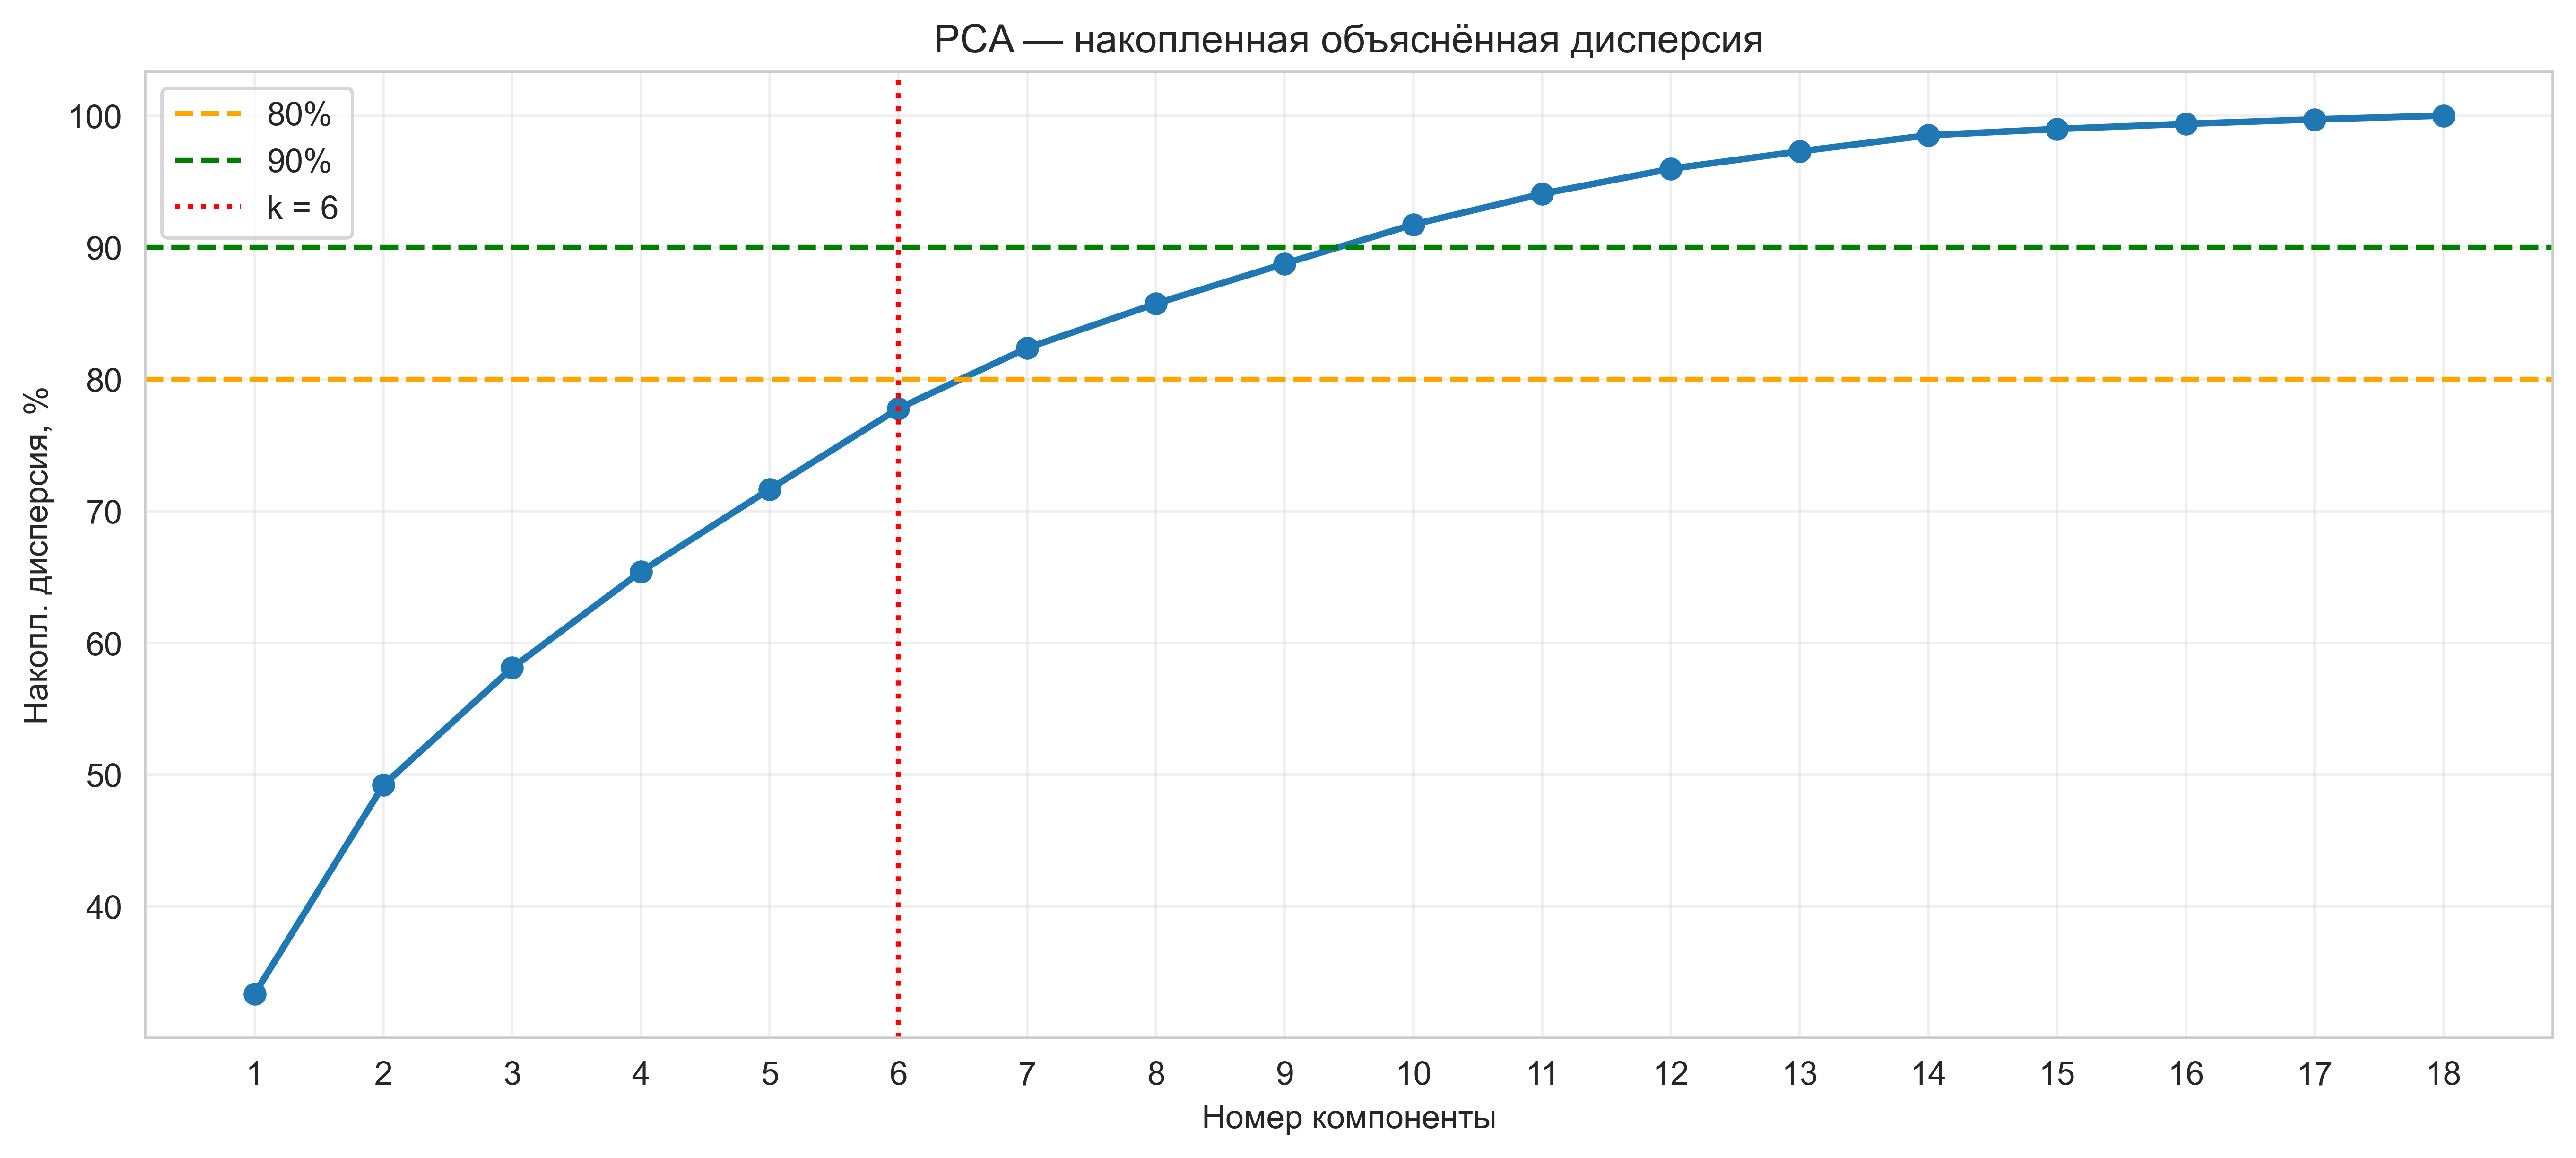

In [49]:
X_std = StandardScaler().fit_transform(X)
pca = PCA()
scores = pca.fit_transform(X_std)

explained = pd.DataFrame({
    'eigenvalue': pca.explained_variance_,
    'variance_%': pca.explained_variance_ratio_ * 100,
})
explained['cumulative_%'] = explained['variance_%'].cumsum()
explained.index = explained.index + 1
explained.index.name = 'Компонента'
display(explained.round(3))
save_excel(explained, '02_собственные_значения')

kaiser_k = int((pca.explained_variance_ > 1).sum())
cum80_k  = int(np.argmax(np.cumsum(pca.explained_variance_ratio_) >= 0.80) + 1)
cum90_k  = int(np.argmax(np.cumsum(pca.explained_variance_ratio_) >= 0.90) + 1)
print(f'Кайзер > 1: {kaiser_k} | 80%: {cum80_k} | 90%: {cum90_k}')

N_COMPONENTS = kaiser_k
print(f'Выбрано k = {N_COMPONENTS}, накопл. дисперсия = {explained.loc[N_COMPONENTS, "cumulative_%"]:.2f}%')

plt.figure(figsize=(11, 5))
plt.plot(explained.index, explained['cumulative_%'], marker='o', lw=2)
plt.axhline(80, ls='--', c='orange', label='80%')
plt.axhline(90, ls='--', c='green',  label='90%')
plt.axvline(N_COMPONENTS, ls=':', c='red', label=f'k = {N_COMPONENTS}')
plt.xlabel('Номер компоненты'); plt.ylabel('Накопл. дисперсия, %')
plt.title('PCA — накопленная объяснённая дисперсия')
plt.xticks(explained.index); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '01_накопленная_дисперсия.png'), dpi=150, bbox_inches='tight')
plt.show()

,PC1,PC2,PC3,PC4,PC5,PC6
k1,0.8,,,,,
k2,0.71,,,,,
k3,0.8,,,,,
k4,0.75,,,,,
k5,0.51,0.62,,,,
k6,,,,,,0.74
k7,0.53,,,,,0.54
k9,0.49,0.73,,,,
k10,,-0.61,-0.47,-0.44,,
k11,,,0.61,,,


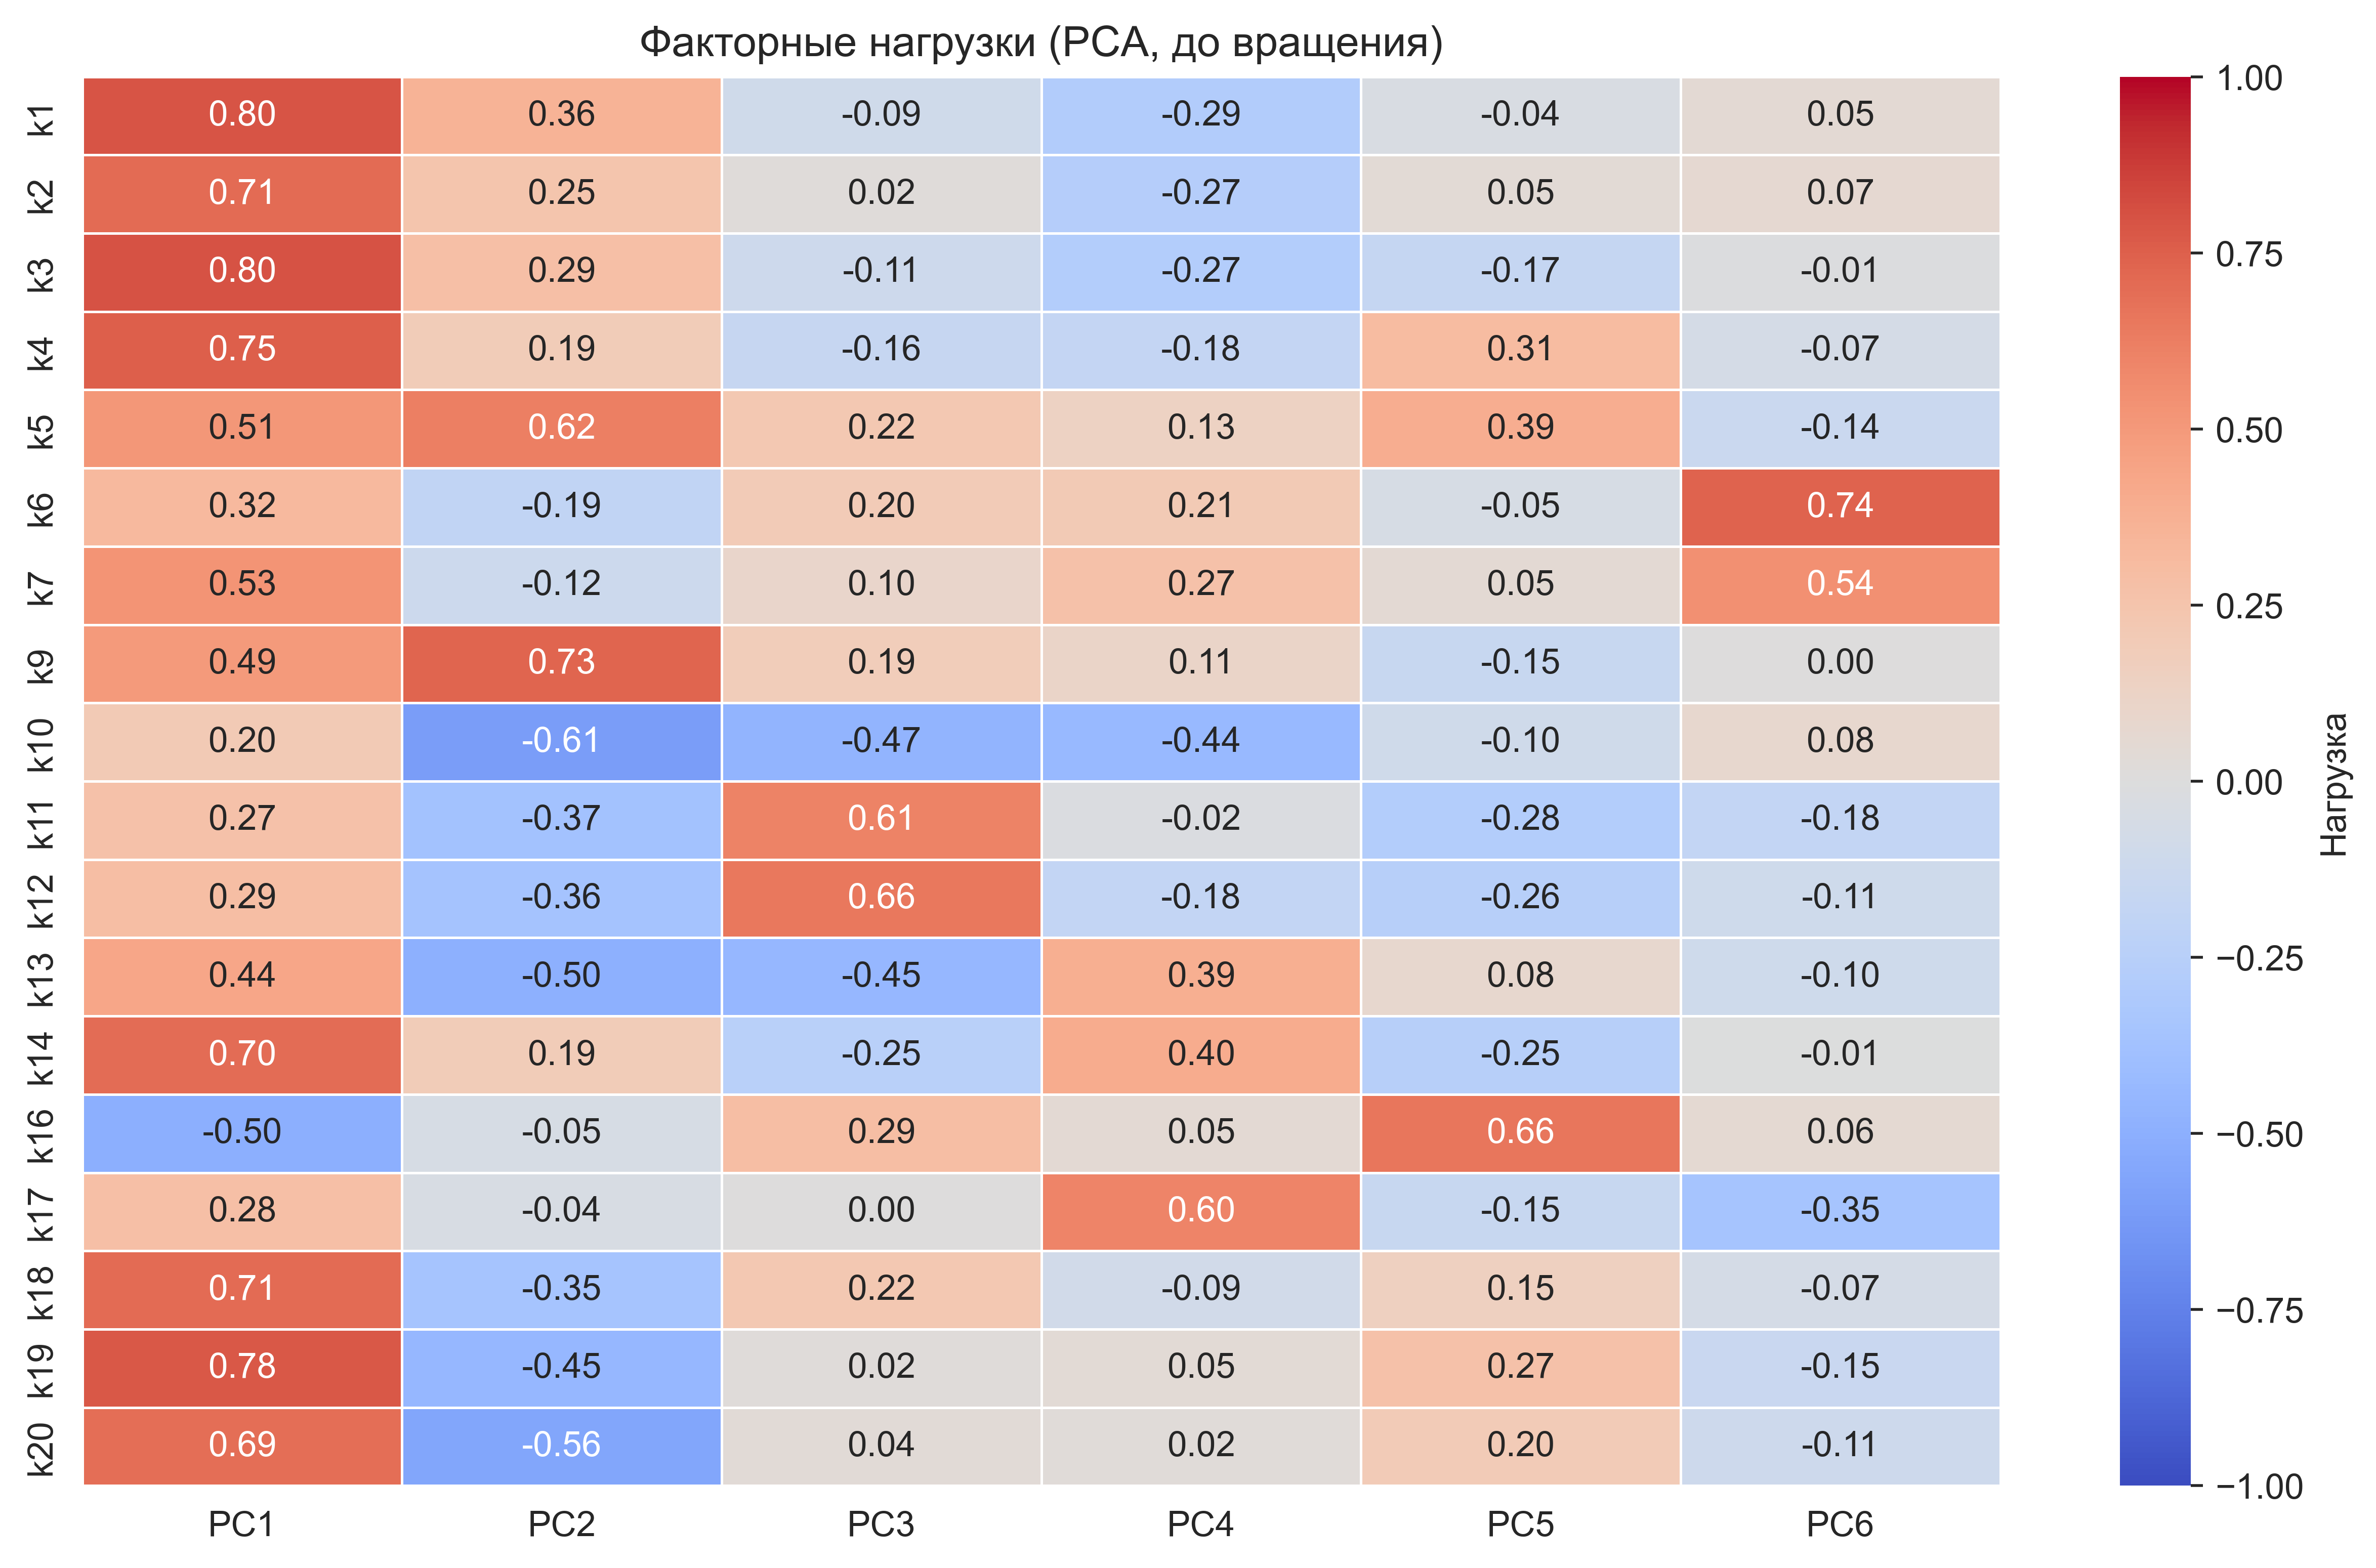

In [50]:
k = N_COMPONENTS
loadings = pd.DataFrame(
    pca.components_[:k].T * np.sqrt(pca.explained_variance_[:k]),
    index=X.columns,
    columns=[f'PC{i+1}' for i in range(k)],
)

significant = loadings.where(loadings.abs() >= 0.4)
display(significant.round(2).fillna(''))
save_excel(significant.fillna(''), '03_значимые_нагрузки_до_вращения')

plt.figure(figsize=(10, max(6, 0.35 * len(loadings))))
sns.heatmap(loadings, annot=True, fmt='.2f', vmin=-1, vmax=1,
            cmap='coolwarm', linewidths=0.5, cbar_kws={'label': 'Нагрузка'})
plt.title('Факторные нагрузки (PCA, до вращения)')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '02_нагрузки_до_вращения_heatmap.png'), dpi=150, bbox_inches='tight')
plt.show()

,communality
Коэффициент,
k19,0.901
k5,0.886
k1,0.859
k20,0.846
k9,0.845
k10,0.837
k3,0.836
k14,0.812
k13,0.806


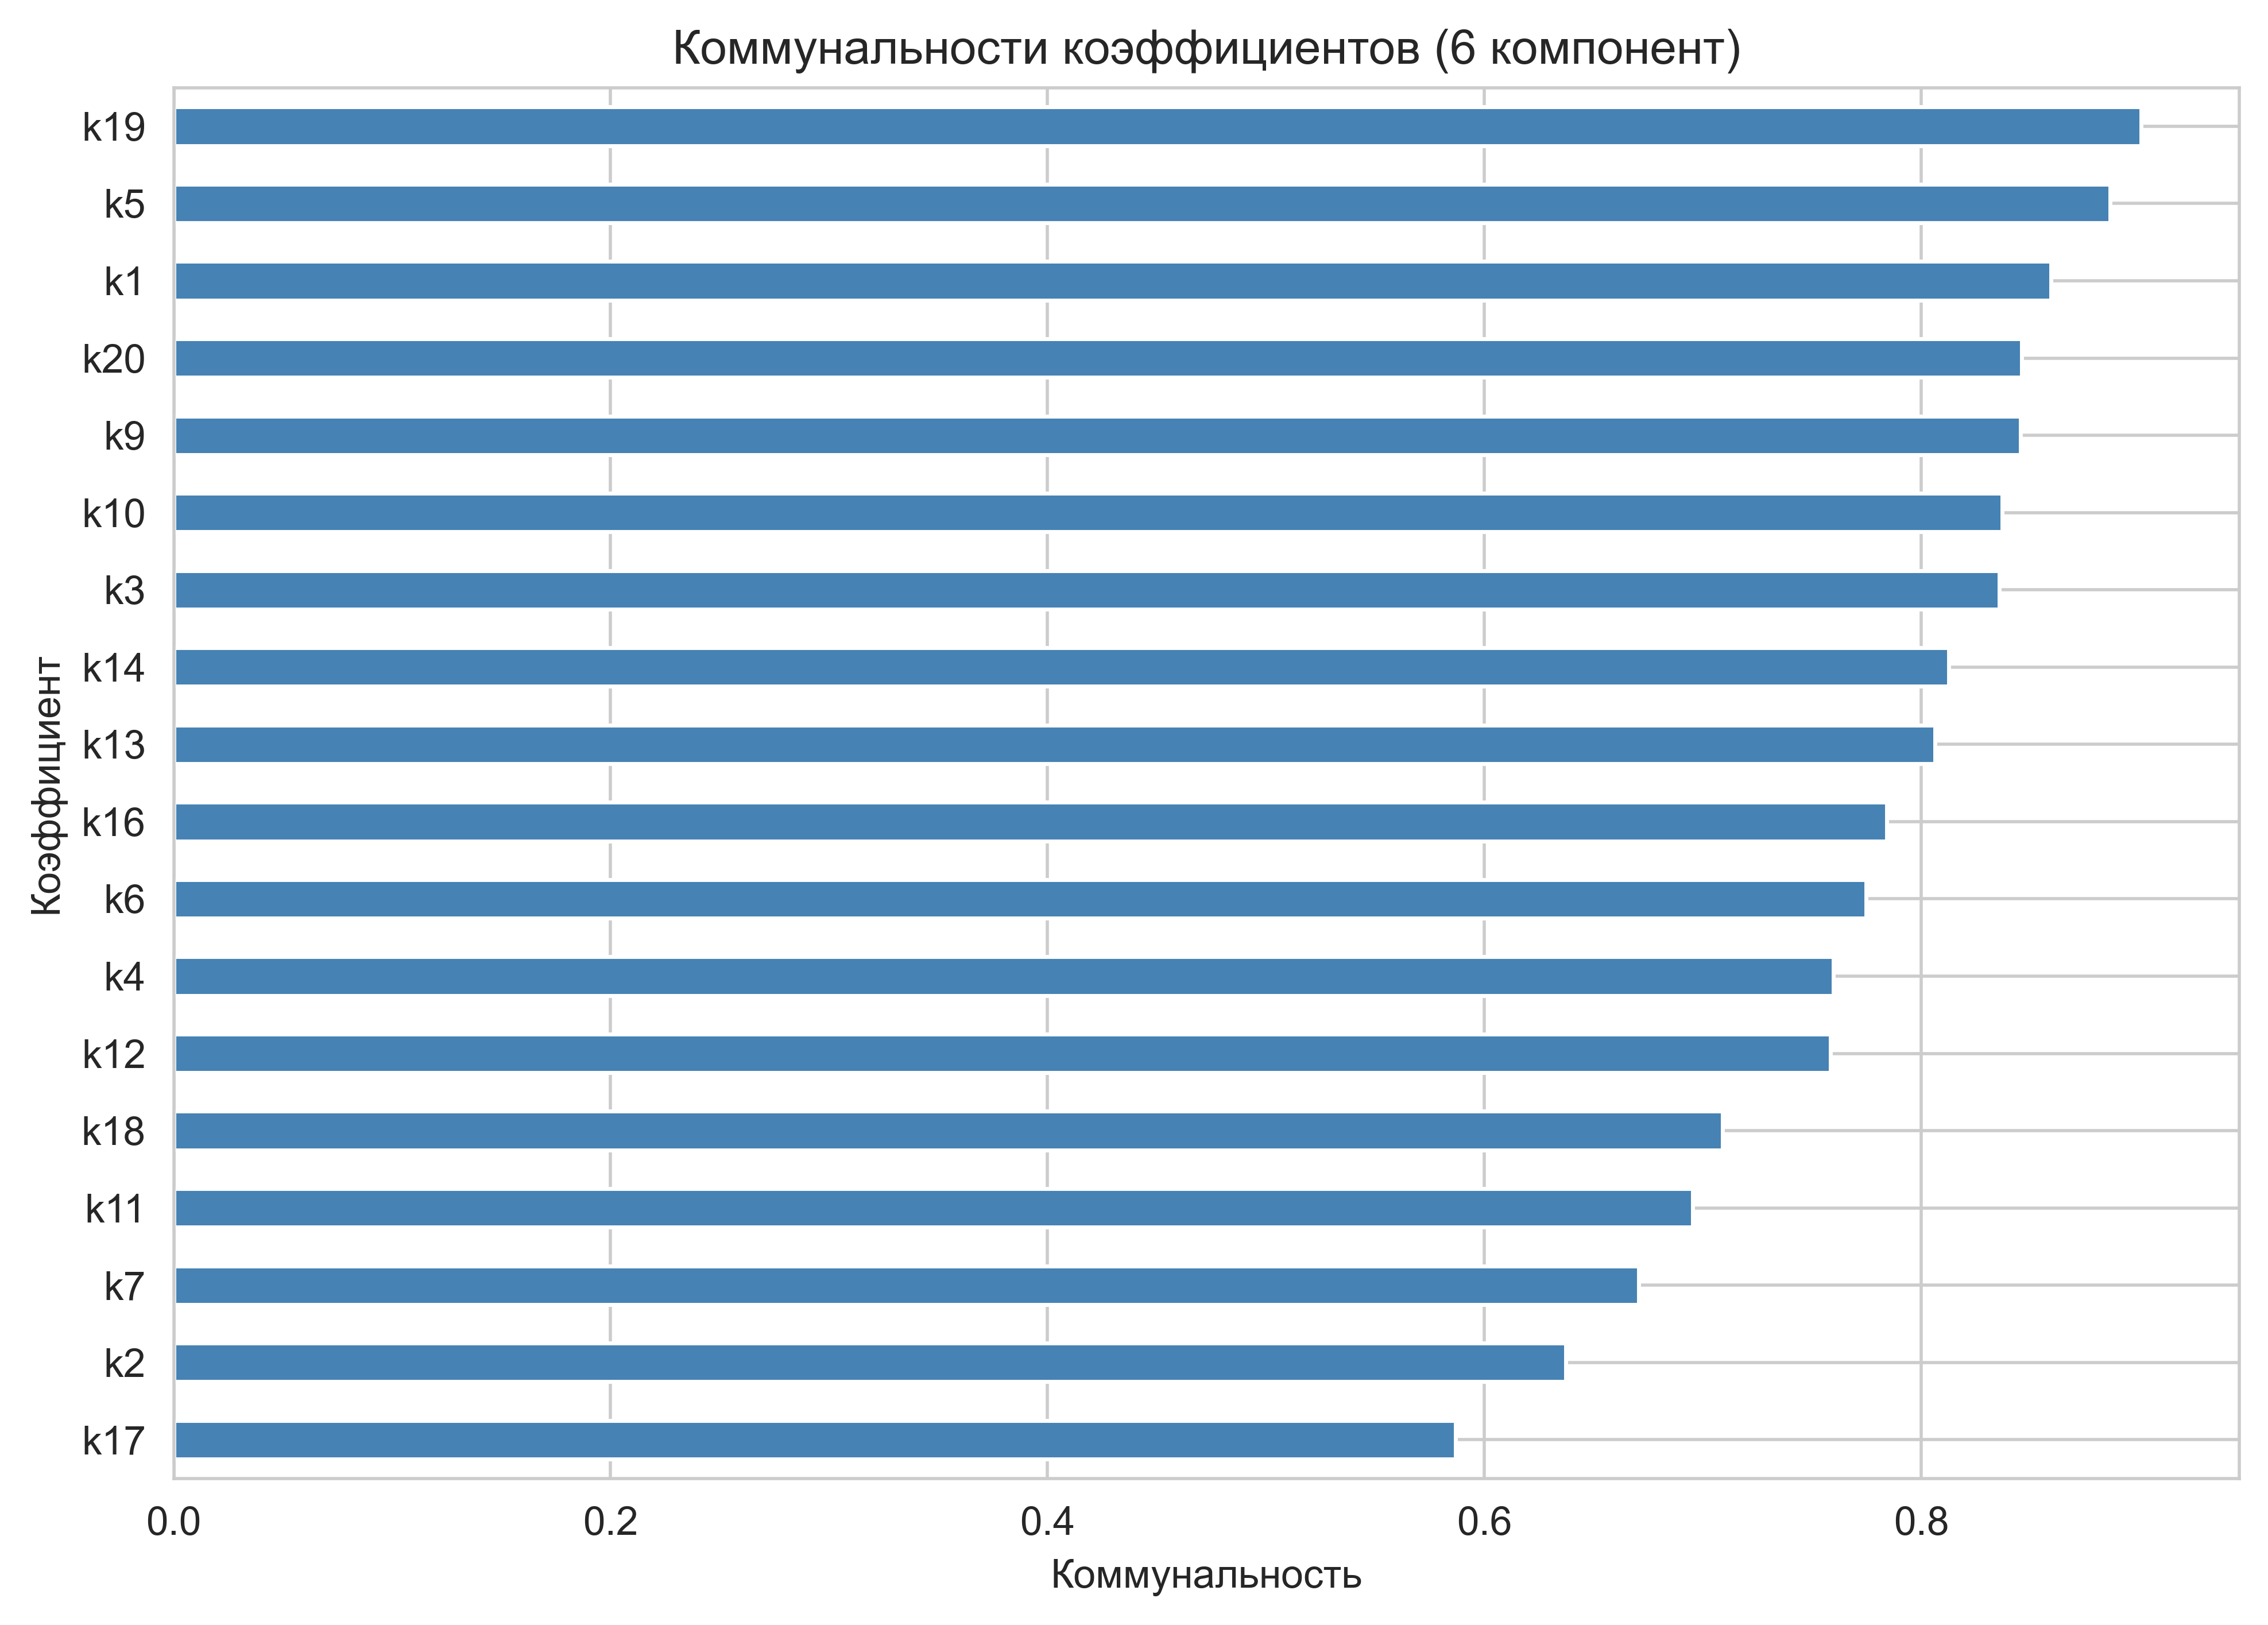

In [51]:
communalities = (loadings ** 2).sum(axis=1).rename('communality').sort_values(ascending=False)
communalities_df = communalities.to_frame()
communalities_df.index.name = 'Коэффициент'
save_excel(communalities_df, '04_коммунальности')
display(communalities_df.round(3))

plt.figure(figsize=(8, max(5, 0.32 * len(communalities))))
communalities.sort_values().plot(kind='barh', color='steelblue')
plt.xlabel('Коммунальность')
plt.title(f'Коммунальности коэффициентов ({k} компонент)')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '03_коммунальности.png'), dpi=150, bbox_inches='tight')
plt.show()

веса (доли дисперсии после квартимакс):
F1: 0.3236
F2: 0.1213
F3: 0.121
F4: 0.2383
F5: 0.1002
F6: 0.0957
corr(integral, ref) = +0.872


,F1,F2,F3,F4,F5,F6
k1,0.91,,,,,
k2,0.76,,,,,
k3,0.88,,,,,
k4,0.73,,,0.43,,
k5,0.62,0.68,,,,
k6,,,,,,0.86
k7,,,,,,0.7
k9,0.72,0.45,,,,
k10,,-0.82,,,,
k11,,,0.79,,,


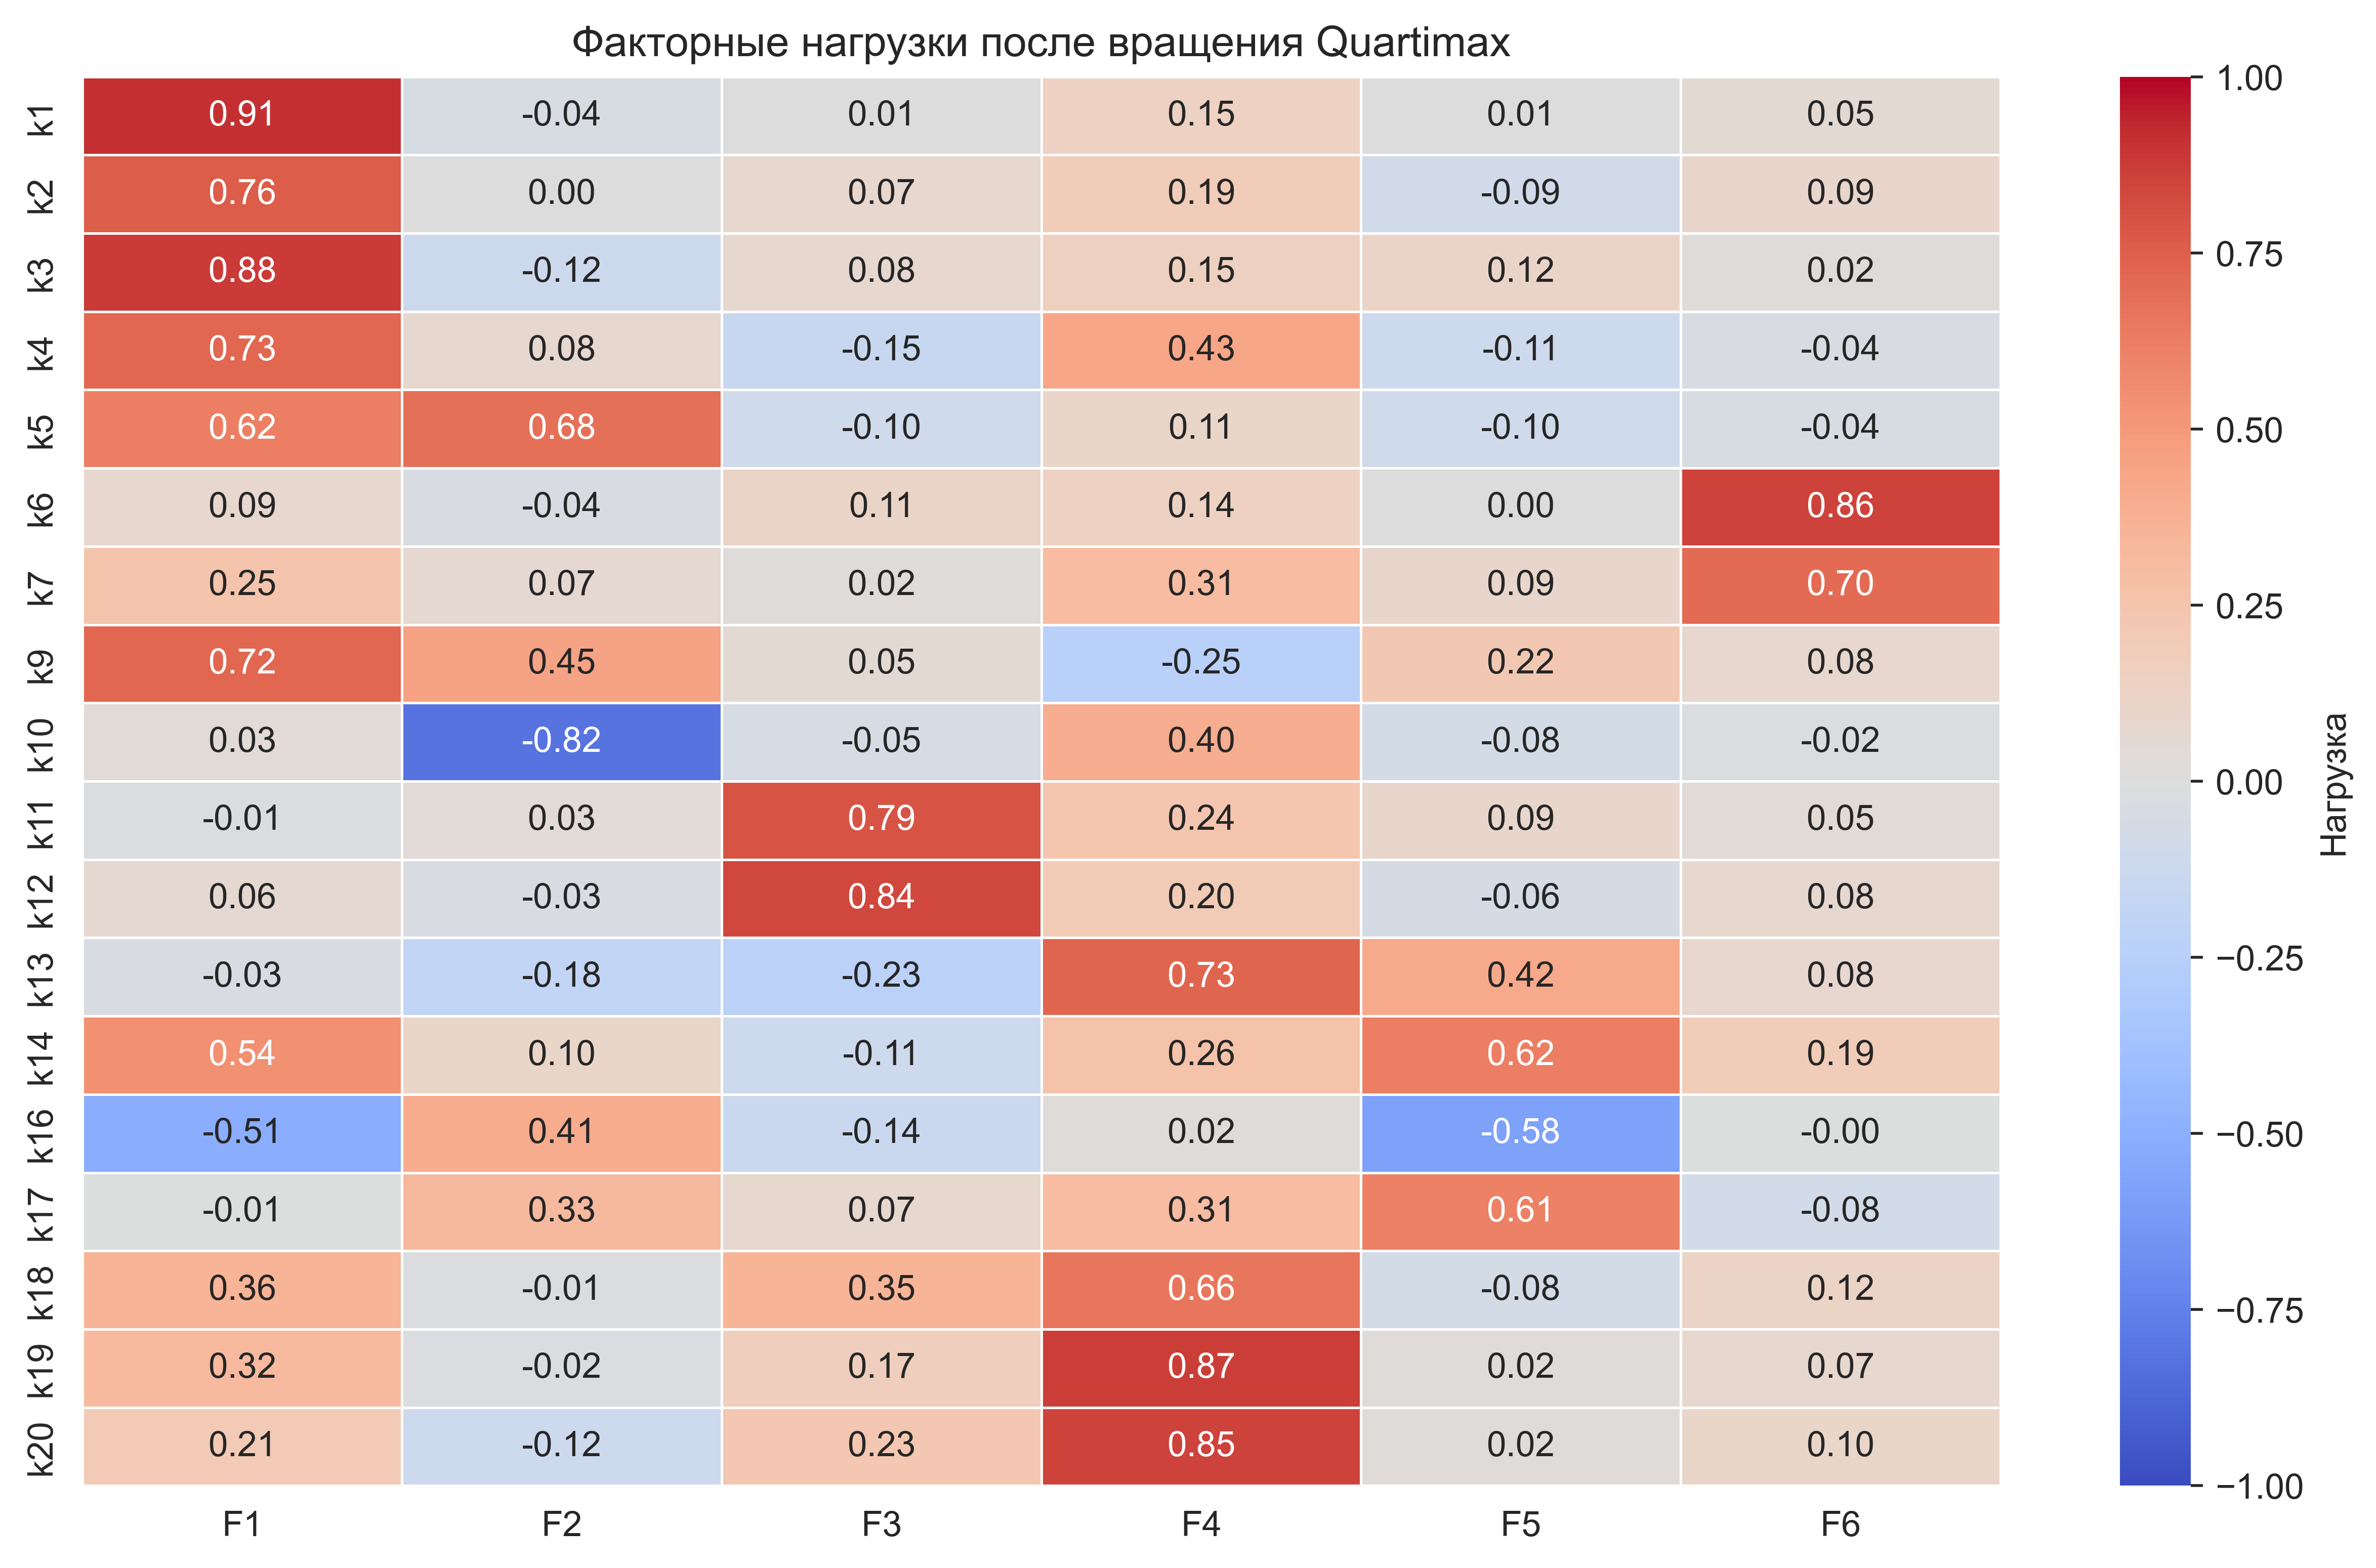

,F1,F2,F3,F4,F5,F6
Собственные значения,4.530,1.698,1.694,3.336,1.403,1.340
% объясненной дисперсии,25.165,9.431,9.410,18.533,7.794,7.444
Кумулятивный %,25.165,34.597,44.007,62.541,70.335,77.779


In [52]:
_orig_check_array = check_array
def _patched_check_array(*args, **kwargs):
    if 'force_all_finite' in kwargs and 'ensure_all_finite' in inspect.signature(_orig_check_array).parameters:
        kwargs['ensure_all_finite'] = kwargs.pop('force_all_finite')
    return _orig_check_array(*args, **kwargs)

fa_module.check_array = _patched_check_array

fa = FactorAnalyzer(n_factors=N_COMPONENTS, rotation='quartimax', method='principal')
fa.fit(X)

rot_scores    = fa.transform(X)
var_after_rot = fa.get_factor_variance()         

rot_loadings = pd.DataFrame(
    fa.loadings_,
    index=X.columns,
    columns=[f'F{i+1}' for i in range(N_COMPONENTS)]
)

w_rot = var_after_rot[1].copy()
w_rot = w_rot / w_rot.sum()
print('веса (доли дисперсии после квартимакс):')
for factor, weight in zip([f'F{i+1}' for i in range(N_COMPONENTS)], w_rot.round(4)):
    print(f'{factor}: {weight}')

integral = pd.Series(rot_scores @ w_rot, index=X.index, name='integral')

good_cols = [c for c in ['k1', 'k2', 'k3', 'k19', 'k20'] if c in X.columns]
ref = X[good_cols].mean(axis=1).values
r_sign = np.corrcoef(integral.values, ref)[0, 1]
print(f'corr(integral, ref) = {r_sign:+.3f}')
if r_sign < 0:
    integral     = -integral
    rot_scores   = -rot_scores
    rot_loadings = -rot_loadings
    fa.loadings_ = -fa.loadings_
    print('знак интеграла и факторов инвертирован')

sig_rot = rot_loadings.where(rot_loadings.abs() >= 0.4)
display(sig_rot.round(2).fillna(''))
save_excel(sig_rot.fillna(''), '06_значимые_нагрузки_после_квартимакс')

plt.figure(figsize=(10, max(6, 0.35 * len(rot_loadings))))
sns.heatmap(rot_loadings, annot=True, fmt='.2f', vmin=-1, vmax=1,
            cmap='coolwarm', linewidths=0.5, cbar_kws={'label': 'Нагрузка'})
plt.title('Факторные нагрузки после вращения Quartimax')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '04_нагрузки_после_квартимакс_heatmap.png'),
            dpi=150, bbox_inches='tight')
plt.show()

var_rot = pd.DataFrame(
    np.round([var_after_rot[0],
              var_after_rot[1] * 100,
              var_after_rot[2] * 100], 3),
    index=['Собственные значения', '% объясненной дисперсии', 'Кумулятивный %'],
    columns=[f'F{i+1}' for i in range(N_COMPONENTS)]
)
display(var_rot)
save_excel(var_rot, '07_дисперсия_после_квартимакс')

,integral
count,2695.0000
mean,0.0000
std,0.4584
min,-1.3385
25%,-0.3260
50%,-0.0311
75%,0.3111
max,1.2745


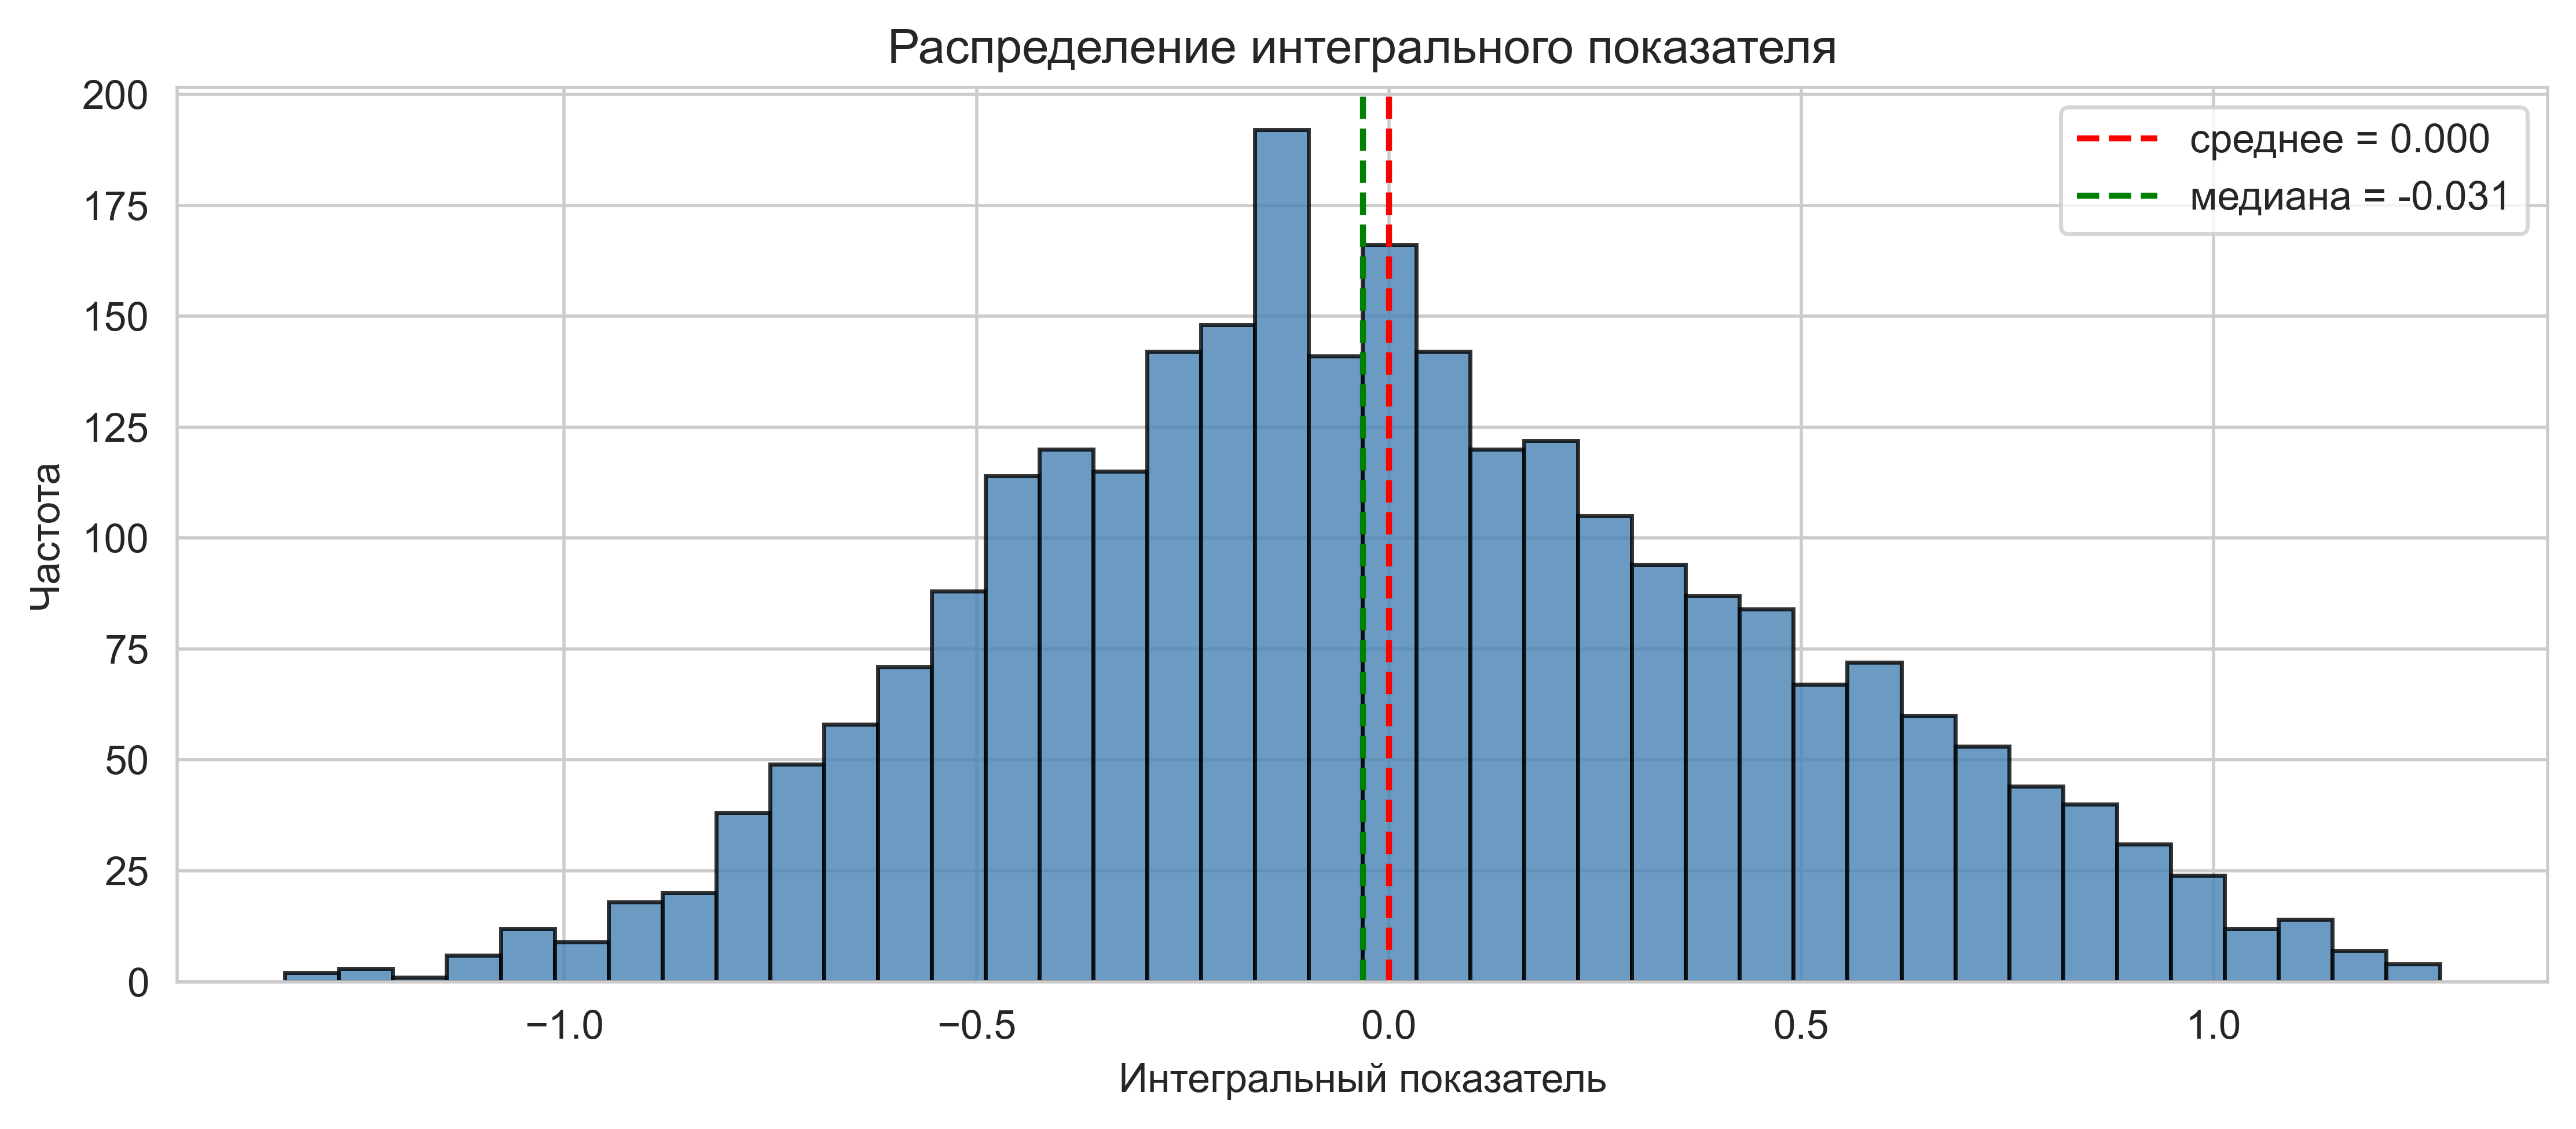

сохранено в c:\Users\HP\source\repos\bsu\sem5\data science\laba 2\результаты


In [53]:
display(integral.describe().to_frame('integral').round(4))
save_excel(integral.describe().to_frame('integral'), '05_описательные_интеграла')

plt.figure(figsize=(9, 4))
plt.hist(integral, bins=40, color='steelblue', edgecolor='black', alpha=0.8)
plt.axvline(integral.mean(),   ls='--', c='red',   label=f'среднее = {integral.mean():.3f}')
plt.axvline(integral.median(), ls='--', c='green', label=f'медиана = {integral.median():.3f}')
plt.xlabel('Интегральный показатель'); plt.ylabel('Частота')
plt.title('Распределение интегрального показателя')
plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '05_гистограмма_интеграла.png'),
            dpi=150, bbox_inches='tight')
plt.show()

save_pickle(X, 'X_norm')
save_pickle(X_std, 'X_std')
save_pickle(scores, 'pca_scores')            
save_pickle(rot_scores, 'fa_scores_rotated')     
save_pickle(rot_loadings, 'fa_loadings_rotated')   
save_pickle(w_rot, 'fa_weights_rotated')    
save_pickle(integral, 'integral')
save_pickle(loadings, 'loadings')
save_pickle(communalities,'communalities')

save_pickle({'N_COMPONENTS': N_COMPONENTS,
             'kmo_total':    kmo_total,
             'p_bartlett':   p_final,
             'chi2':         chi2_final,
             'w_rot':        w_rot},                
            'pca_summary')
print('сохранено в', RESULT_DIR)

,Метод,Trustworthiness
0,t-SNE,0.9341
1,UMAP,0.9237
2,PCA,0.8406
3,Isomap,0.8377


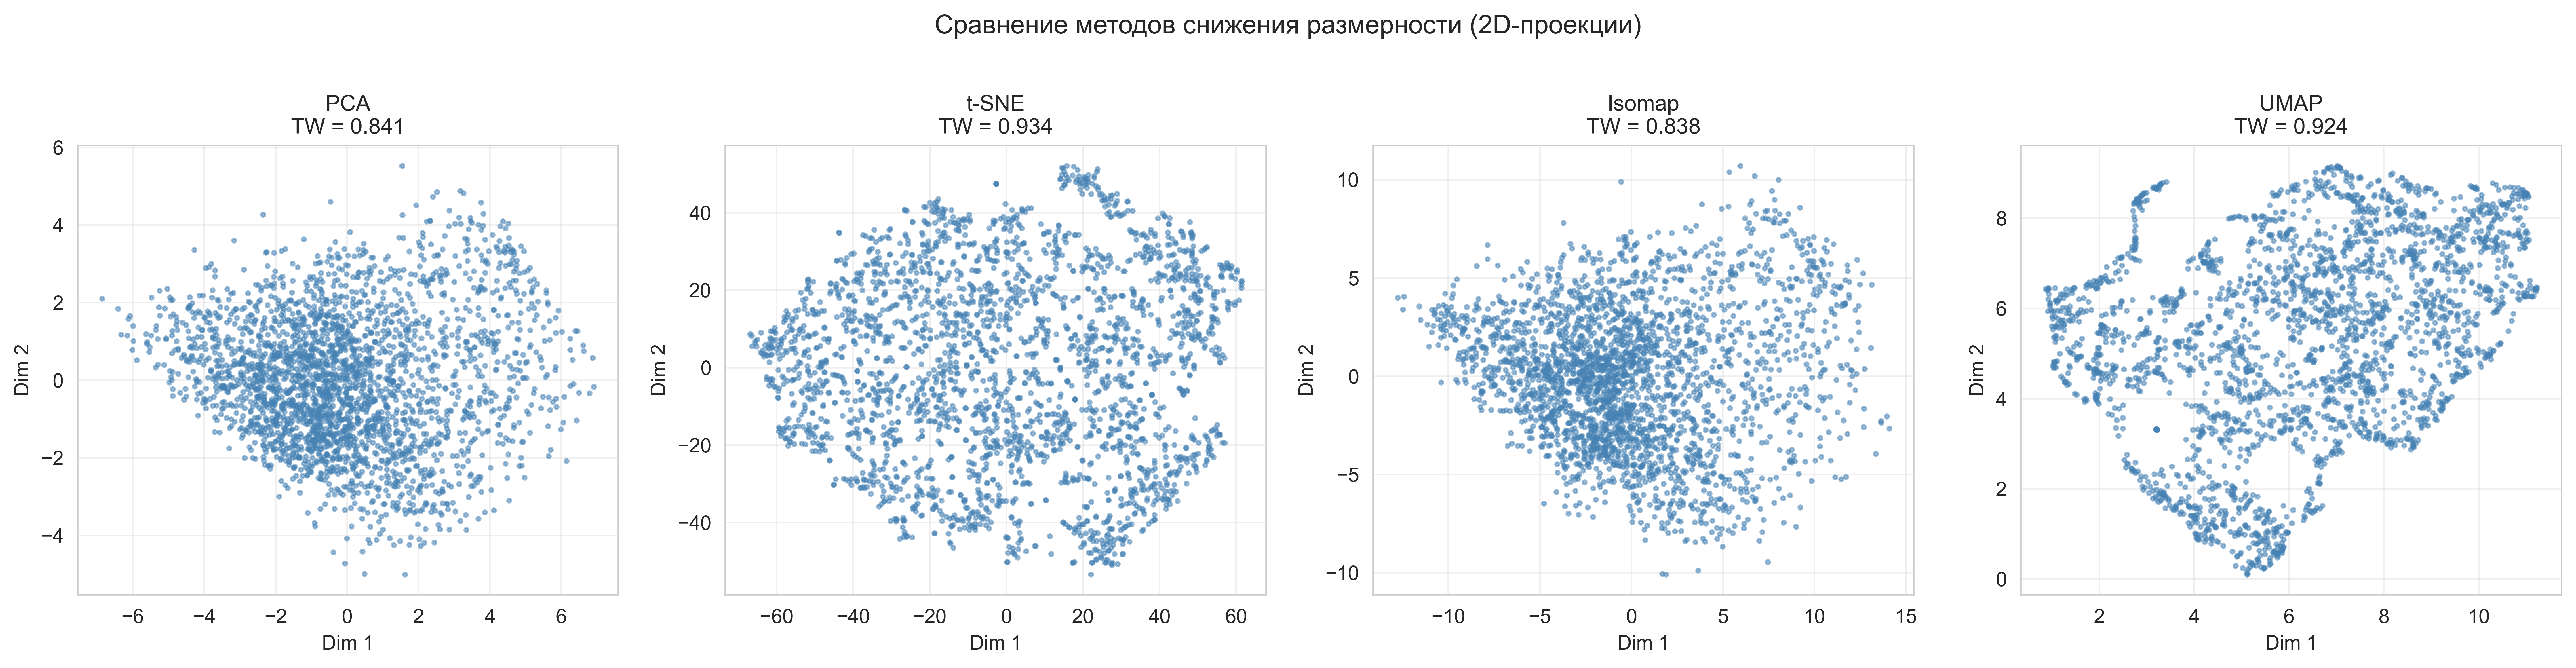

In [54]:
X_orig = X_std
n_samples = X_orig.shape[0]

k_tw      = max(10, min(50, int(np.sqrt(n_samples)))) 
perplexity = min(50, max(5, n_samples // 100))         
k_isomap  = max(5, int(np.log(n_samples)))            
k_umap    = max(2, int(np.log2(n_samples)))           
min_dist  = 0.1                                        

projections = {}
tw_scores   = {}

pca_2d = scores[:, :2]
projections['PCA'] = pca_2d
tw_scores['PCA']   = trustworthiness(X_orig, pca_2d, n_neighbors=k_tw)

tsne = TSNE(n_components=2, perplexity=perplexity, max_iter=1000,
            random_state=42, init='pca', learning_rate='auto')
tsne_2d = tsne.fit_transform(X_orig)
projections['t-SNE'] = tsne_2d
tw_scores['t-SNE']   = trustworthiness(X_orig, tsne_2d, n_neighbors=k_tw)

isomap = Isomap(n_components=2, n_neighbors=k_isomap)
isomap_2d = isomap.fit_transform(X_orig)
projections['Isomap'] = isomap_2d
tw_scores['Isomap']   = trustworthiness(X_orig, isomap_2d, n_neighbors=k_tw)

reducer = umap.UMAP(n_components=2, n_neighbors=k_umap, min_dist=min_dist,
                    random_state=42)
umap_2d = reducer.fit_transform(X_orig)
projections['UMAP'] = umap_2d
tw_scores['UMAP']   = trustworthiness(X_orig, umap_2d, n_neighbors=k_tw)

tw_df = (pd.DataFrame(list(tw_scores.items()), columns=['Метод', 'Trustworthiness'])
           .sort_values('Trustworthiness', ascending=False)
           .reset_index(drop=True))
display(tw_df.round(4))
save_excel(tw_df.set_index('Метод'), '08_trustworthiness_методов')

n_methods = len(projections)
fig, axes = plt.subplots(1, n_methods, figsize=(4.5 * n_methods, 4.5))
for ax, (name, proj) in zip(axes, projections.items()):
    ax.scatter(proj[:, 0], proj[:, 1], s=4, alpha=0.5, c='steelblue')
    ax.set_title(f'{name}\nTW = {tw_scores[name]:.3f}', fontsize=11)
    ax.set_xlabel('Dim 1'); ax.set_ylabel('Dim 2')
    ax.grid(alpha=0.3)

plt.suptitle('Сравнение методов снижения размерности (2D-проекции)', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '06_сравнение_методов_снижения_размерности.png'),
            dpi=150, bbox_inches='tight')
plt.show()

save_pickle(projections, 'dim_reduction_projections')
save_pickle(tw_scores,   'trustworthiness_scores')